# S&P 500 Stock Market Performance – Track A (Data Analytics)
AnalystLab Africa Week 6. This notebook runs the project scripts, shows their outputs and explains each result. Historical, price-only, 2014–2017; not investment advice.

## 1. Setup and data inspection (Task 1)

In [1]:
import os, json, pandas as pd, numpy as np
from IPython.display import Image, display, HTML
os.chdir(os.path.abspath('..')) if os.path.basename(os.getcwd())=='notebooks' else None
pd.set_option('display.width',160); pd.set_option('display.max_columns',30)
raw = pd.read_csv('data/raw/sp500_stock_prices_cleaned.csv', low_memory=False, parse_dates=['date'])
print(raw.shape); display(raw.head()); display(raw.dtypes.to_frame('dtype').T)

(497464, 8)


,symbol,date,open,high,low,close,volume,data_note
0,A,2014-01-02,57.1000,57.1000,56.1500,56.2100,1916160,NaN
1,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943,NaN
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711,NaN
3,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957,NaN
4,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061,NaN


,symbol,date,open,high,low,close,volume,data_note
dtype,str,datetime64[us],float64,float64,float64,float64,int64,str


In [2]:
print('missing values:'); print(raw.isna().sum().to_string())
print('duplicate symbol-date pairs:', raw.duplicated(['symbol','date']).sum())
print('zero-volume rows:', (raw.volume==0).sum())
print('symbols:', raw.symbol.nunique(), '| trading dates:', raw.date.nunique(), '|', raw.date.min().date(), 'to', raw.date.max().date())
print('sorted by symbol,date?', raw.equals(raw.sort_values(['symbol','date']).reset_index(drop=True)))
display(raw.data_note.value_counts())
c = raw.groupby('symbol').size(); print('symbols with incomplete history:', (c<raw.date.nunique()).sum())

missing values:
symbol            0
date              0
open              0
high              0
low               0
close             0
volume            0
data_note    497449
duplicate symbol-date pairs: 0
zero-volume rows: 0
symbols: 505 | trading dates: 1007 | 2014-01-02 to 2017-12-29
sorted by symbol,date? False


data_note
high/low expanded to cover open/close              8
OHLC inconsistent, kept (likely split/spin-off)    4
open filled with prior close                       3
Name: count, dtype: int64

symbols with incomplete history: 28


**Reading:** the supplied file is already partly cleaned: no missing values and no zero-volume rows (the brief reports 11/8/8 missing and 4 zero-volume), 497,464 rows rather than 497,472, and an extra `data_note` column recording 15 upstream repairs. It is sorted by date, so it is re-sorted by symbol and date before any return is calculated. 28 symbols have incomplete histories. See `docs/data_quality_assessment.md`.

## 2. Cleaning and feature engineering (Task 2)

In [3]:
%run scripts/01_prepare_data.py

{
  "rows": 497464,
  "columns": [
    "symbol",
    "date",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "data_note"
  ],
  "symbols": 505,
  "trading_dates": 1007,
  "date_min": "2014-01-02",
  "date_max": "2017-12-29",
  "missing_by_column": {
    "symbol": 0,
    "date": 0,
    "open": 0,
    "high": 0,
    "low": 0,
    "close": 0,
    "volume": 0,
    "data_note": 497449
  },
  "duplicate_symbol_date": 0,
  "zero_volume_rows": 0,
  "nonpositive_price_rows": 0,
  "originally_sorted_by_symbol_date": false,
  "data_note_counts": {
    "high/low expanded to cover open/close": 8,
    "OHLC inconsistent, kept (likely split/spin-off)": 4,
    "open filled with prior close": 3
  },
  "ohlc_inconsistent_rows": 4,
  "symbols_with_incomplete_history": 28,
  "suspect_return_rows": 21,
  "suspect_rows_list": [
    {
      "symbol": "ARNC",
      "date": "2016-11-01",
      "daily_return_pct": -34.12
    },
    {
      "symbol": "BAX",
      "date": "2015-07-01",
      "da

In [4]:
df = pd.read_parquet('data/processed/sp500_prepared.parquet')
display(df[df.symbol=='AAPL'].iloc[18:24][['symbol','date','close','year','quarter','daily_change','daily_return_pct','daily_range','ma_5','ma_20']])
flag = df[df.suspect_return_flag][['symbol','date','daily_return_pct','data_note']]
print(len(flag),'flagged rows'); display(flag.round(2))

,symbol,date,close,year,quarter,daily_change,daily_return_pct,daily_range,ma_5,ma_20
3039,AAPL,2014-01-29,71.5356,2014,1,-0.8215,-1.135341,1.2500,75.99992,NaN
3040,AAPL,2014-01-30,71.3974,2014,1,-0.1382,-0.193191,1.4000,74.38856,77.041060
3041,AAPL,2014-01-31,71.5142,2014,1,0.1168,0.163591,1.1400,73.08942,76.665845
3042,AAPL,2014-02-03,71.6471,2014,1,0.1329,0.185837,1.2043,71.69028,76.384060
3043,AAPL,2014-02-04,72.6842,2014,1,1.0371,1.447511,0.9571,71.75570,76.133060
3044,AAPL,2014-02-05,73.2271,2014,1,0.5429,0.746930,1.2898,72.09400,75.937010


21 flagged rows


/tmp/ipykernel_4098/1765183786.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(len(flag),'flagged rows'); display(flag.round(2))


,symbol,date,daily_return_pct,data_note
50075,ARNC,2016-11-01,-34.12,NaN
60814,BAX,2015-07-01,-44.43,NaN
66597,BHGE,2017-07-05,-35.42,NaN
91808,CHD,2014-05-19,0.07,"OHLC inconsistent, kept (likely split/spin-off)"
135687,DISCA,2014-08-07,-50.64,NaN
136694,DISCK,2014-08-07,-51.02,NaN
150295,EBAY,2015-07-20,-56.90,NaN
187352,FLR,2017-09-14,26.11,NaN
187353,FLR,2017-09-15,-20.13,NaN
281854,LNT,2016-05-19,-49.45,"OHLC inconsistent, kept (likely split/spin-off)"


**Reading:** every engineered field is grouped by symbol, so the first row of each stock has no return and the first 19 rows have no 20-day average (nothing is filled with zero). The 21 flagged rows are probable splits, spin-offs, a special dividend and bad prints; they are excluded from return statistics but the raw return is kept.

## 3. Analysis (Tasks 3 and 4)

In [5]:
%run scripts/02_analysis_and_charts.py

/home/claude/Week6_DataAnalytics/scripts/02_analysis_and_charts.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  s.round(4).to_csv(TAB / "symbol_summary_all_505.csv")
/home/claude/Week6_DataAnalytics/scripts/02_analysis_and_charts.py:75: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  cmp.round(3).to_csv(TAB / "task4_selected_comparison.csv")


done
        mean_close  median_close  min_close min_close_date  max_close max_close_date  total_return_pct  total_return_raw_pct  mean_daily_return_pct  daily_vol_pct  annualised_vol_pct   avg_volume  max_volume  min_volume
symbol                                                                                                                                                                                                                     
AAPL        116.84        113.05      71.40     2014-01-30     176.42     2017-12-18            114.17                114.17                   0.09           1.43               22.71  45169571.17   266833581    11475922
MSFT         54.08         51.30      34.98     2014-01-13      86.85     2017-12-15            130.19                130.19                   0.09           1.37               21.74  30712613.15   202526536     7425603
AMZN        619.24        591.43     286.95     2015-01-15    1195.83     2017-11-27            193.86             

/home/claude/Week6_DataAnalytics/scripts/02_analysis_and_charts.py:164: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print("done"); print(cmp.round(2).to_string()); print(corr.round(2)); print(pd.Series(vol_ret_corr).round(3)); print(pd.Series(absr).round(3))


In [6]:
T = lambda f: pd.read_csv(f'docs/tables/{f}.csv')
for name,f in [('Q1 Highest closing prices','q1_highest_closing_prices'),('Q1 Lowest closing prices','q1_lowest_closing_prices'),('Q2 Highest total return','q2_top10_total_return'),('Q2 Lowest total return','q2_bottom10_total_return')]:
    print(name); display(T(f).round(2))

Q1 Highest closing prices


,symbol,max_close,max_close_date
0,PCLN,2049.00,2017-08-08
1,AMZN,1195.83,2017-11-27
2,GOOGL,1085.09,2017-12-18
3,GOOG,1077.14,2017-12-18
4,AZO,815.98,2016-07-28
5,CMG,757.77,2015-08-05
6,MTD,689.11,2017-11-01
7,REGN,592.40,2015-08-05
8,BLK,518.86,2017-12-18
9,EQIX,492.98,2017-11-08


Q1 Lowest closing prices


,symbol,min_close,min_close_date
0,CHK,1.59,2016-02-12
1,AMD,1.62,2015-07-27
2,FCX,3.74,2016-01-13
3,MRO,6.73,2016-02-19
4,RF,7.08,2016-02-11
5,HBAN,8.01,2016-02-11
6,NAVI,8.41,2016-02-11
7,AES,8.54,2016-01-15
8,NRG,8.98,2016-01-25
9,HPQ,9.02,2016-02-11


Q2 Highest total return


,symbol,total_return_pct,total_return_raw_pct,first_close,last_close,n_suspect_returns
0,NVDA,1120.05,1120.05,15.86,193.50,0
1,AVGO,387.94,387.94,52.65,256.90,0
2,EA,360.18,360.18,22.83,105.06,0
3,ALGN,290.08,290.08,56.96,222.19,0
4,NFLX,270.35,270.35,51.83,191.96,0
5,ATVI,250.42,250.42,18.07,63.32,0
6,LUV,246.66,246.66,18.88,65.45,0
7,SWKS,246.53,246.53,27.40,94.95,0
8,EW,241.96,241.96,32.96,112.71,0
9,CNC,241.73,241.73,29.52,100.88,0


Q2 Lowest total return


,symbol,total_return_pct,total_return_raw_pct,first_close,last_close,n_suspect_returns
0,CHK,-85.12,-85.12,26.62,3.96,0
1,RRC,-79.13,-79.13,81.74,17.06,0
2,MAT,-67.55,-67.55,47.39,15.38,0
3,VIAB,-64.57,-64.57,86.95,30.81,0
4,TRIP,-57.18,-57.18,80.48,34.46,0
5,NBL,-56.24,-56.24,66.59,29.14,0
6,NOV,-54.42,-54.42,79.02,36.02,0
7,M,-52.82,-52.82,53.39,25.19,0
8,MRO,-51.87,-51.50,34.91,16.93,2
9,APA,-50.61,-50.61,85.48,42.22,0


**Q1/Q2 method:** highest and lowest closing price per symbol; total price return = compounded daily returns with flagged days at 0%, ranked over the 477 complete-history symbols. **Interpretation:** the highest prices (PCLN, AMZN, GOOGL) are not the best performers; NVDA (+1,120%) and CHK (−85%) are the extremes. Price level is not performance.

In [7]:
for name,f in [('Q3 Most volatile (annualised %)','q3_most_volatile'),('Q3 Least volatile','q3_least_volatile'),('Q4 Highest average volume','q4_highest_avg_volume'),('Q7 Largest daily gains','q7_largest_daily_gains'),('Q7 Largest daily losses','q7_largest_daily_losses')]:
    print(name); display(T(f).round(2))

Q3 Most volatile (annualised %)


,symbol,annualised_vol_pct,mean_daily_return_pct
0,CHK,72.25,-0.09
1,AMD,62.07,0.17
2,FCX,58.72,-0.00
3,WMB,51.35,0.03
4,MRO,46.42,-0.03
5,RRC,46.15,-0.11
6,INCY,45.34,0.10
7,NFX,44.66,0.07
8,MU,43.98,0.10
9,NRG,43.59,0.04


Q3 Least volatile


,symbol,annualised_vol_pct,mean_daily_return_pct
0,PEP,13.15,0.04
1,PG,13.50,0.02
2,RSG,13.53,0.08
3,KO,13.61,0.02
4,WM,13.69,0.07
5,JNJ,14.11,0.05
6,BRK.B,14.35,0.06
7,CB,14.88,0.04
8,SO,14.93,0.02
9,AJG,14.95,0.04


Q4 Highest average volume


,symbol,avg_volume,max_volume
0,BAC,89362903.70,375088650
1,AAPL,45169571.17,266833581
2,GE,41443942.52,431332632
3,AMD,33289509.07,268336455
4,F,32914300.94,142168574
5,MSFT,30712613.15,202526536
6,FB,29227823.61,150438699
7,MU,27962814.08,149010345
8,CHK,27885401.57,188966428
9,INTC,27161138.32,135893228


Q7 Largest daily gains


,symbol,date,close,daily_change,daily_return_pct
0,AMD,2016-04-22,3.99,1.37,52.29
1,VRTX,2014-06-24,93.53,26.92,40.41
2,CHK,2016-04-12,6.05,1.55,34.44
3,WMB,2016-01-14,18.29,4.68,34.39
4,MNST,2014-08-15,31.16,7.28,30.48
5,NVDA,2016-11-11,87.97,20.20,29.81
6,NRG,2017-07-12,21.09,4.79,29.39
7,FCX,2015-08-27,10.19,2.27,28.66
8,FL,2017-11-17,40.82,8.97,28.16
9,WMB,2015-06-22,60.86,12.52,25.90


Q7 Largest daily losses


,symbol,date,close,daily_change,daily_return_pct
0,WMB,2016-02-08,11.16,-5.96,-34.81
1,EVHC,2017-11-01,28.03,-14.57,-34.20
2,CHK,2016-02-08,2.04,-1.02,-33.33
3,SIG,2017-11-21,52.79,-23.05,-30.39
4,BBY,2014-01-16,26.83,-10.74,-28.59
5,PWR,2015-10-16,18.74,-7.47,-28.50
6,CAG,2016-11-10,34.30,-13.54,-28.30
7,FL,2017-08-18,34.38,-13.32,-27.92
8,NWL,2017-11-02,30.01,-10.99,-26.80
9,A,2014-11-03,40.84,-14.44,-26.12


**Q3 method:** standard deviation of daily returns × √252. **Q4:** mean daily shares traded. **Q7:** largest single-day percentage moves after removing flagged rows. **Interpretation:** the most volatile names (CHK, AMD, FCX) are also those with the largest one-day swings; BAC is the most heavily traded stock, ahead of AAPL.

In [8]:
print('Q5/Q6 selected stocks, calendar-year return %'); display(pd.read_csv('docs/tables/q6_selected_yearly_return.csv', index_col=0))
print('Task 4 comparison'); display(pd.read_csv('docs/tables/task4_selected_comparison.csv', index_col=0).round(2))
print('Return correlation'); display(pd.read_csv('docs/tables/task4_return_correlation.csv', index_col=0))
print(pd.concat([pd.read_csv('docs/tables/task4_volume_return_corr.csv',index_col=0), pd.read_csv('docs/tables/task4_volume_absreturn_corr.csv',index_col=0)],axis=1).to_string())

Q5/Q6 selected stocks, calendar-year return %


,AAPL,MSFT,AMZN,JPM,XOM,JNJ
date,,,,,,
2014,39.69,25.00,-22.02,7.51,-7.32,14.87
2015,-4.64,19.44,117.78,5.51,-15.68,-1.77
2016,10.03,12.00,10.95,30.68,15.79,12.16
2017,46.11,37.66,55.96,23.93,-7.33,21.27


Task 4 comparison


,mean_close,median_close,min_close,min_close_date,max_close,max_close_date,total_return_pct,total_return_raw_pct,mean_daily_return_pct,daily_vol_pct,annualised_vol_pct,avg_volume,max_volume,min_volume
symbol,,,,,,,,,,,,,,
AAPL,116.84,113.05,71.40,2014-01-30,176.42,2017-12-18,114.16,114.16,0.09,1.43,22.72,45169571.17,266833581,11475922
MSFT,54.08,51.30,34.98,2014-01-13,86.85,2017-12-15,130.19,130.19,0.09,1.37,21.74,30712613.15,202526536,7425603
AMZN,619.24,591.43,286.95,2015-01-15,1195.83,2017-11-27,193.86,193.86,0.12,1.86,29.60,3880124.57,23856060,1092970
JPM,69.89,64.04,53.07,2016-02-11,107.83,2017-12-21,83.71,83.71,0.07,1.30,20.55,15680002.05,56192320,3680043
XOM,87.05,85.48,68.71,2015-08-25,104.38,2014-06-23,-16.15,-16.15,-0.01,1.13,17.94,12298770.50,44704931,3851283
JNJ,110.96,106.47,86.62,2014-02-04,143.62,2017-10-23,53.49,53.49,0.05,0.89,14.12,7298176.88,25835156,2353779


Return correlation


,AAPL,MSFT,AMZN,JPM,XOM,JNJ
symbol,,,,,,
AAPL,1.000,0.437,0.339,0.369,0.278,0.295
MSFT,0.437,1.000,0.439,0.438,0.342,0.383
AMZN,0.339,0.439,1.000,0.282,0.234,0.275
JPM,0.369,0.438,0.282,1.000,0.499,0.412
XOM,0.278,0.342,0.234,0.499,1.000,0.423
JNJ,0.295,0.383,0.275,0.412,0.423,1.000


      spearman_volume_vs_return  spearman_volume_vs_abs_return
AAPL                     -0.030                          0.444
MSFT                     -0.006                          0.465
AMZN                      0.013                          0.497
JPM                      -0.040                          0.514
XOM                      -0.015                          0.472
JNJ                      -0.032                          0.442


**Reading:** over 2014–2017 AMZN (+193.9%) and MSFT (+130.2%) led the six, XOM (−16.2%) lagged; JNJ had the lowest volatility (14.1%). Daily returns are only moderately correlated (0.23–0.50). Volume has almost no rank correlation with the signed return but 0.44–0.51 with the size of the move.

## 4. Visualisations

01_indexed_price_selected.png


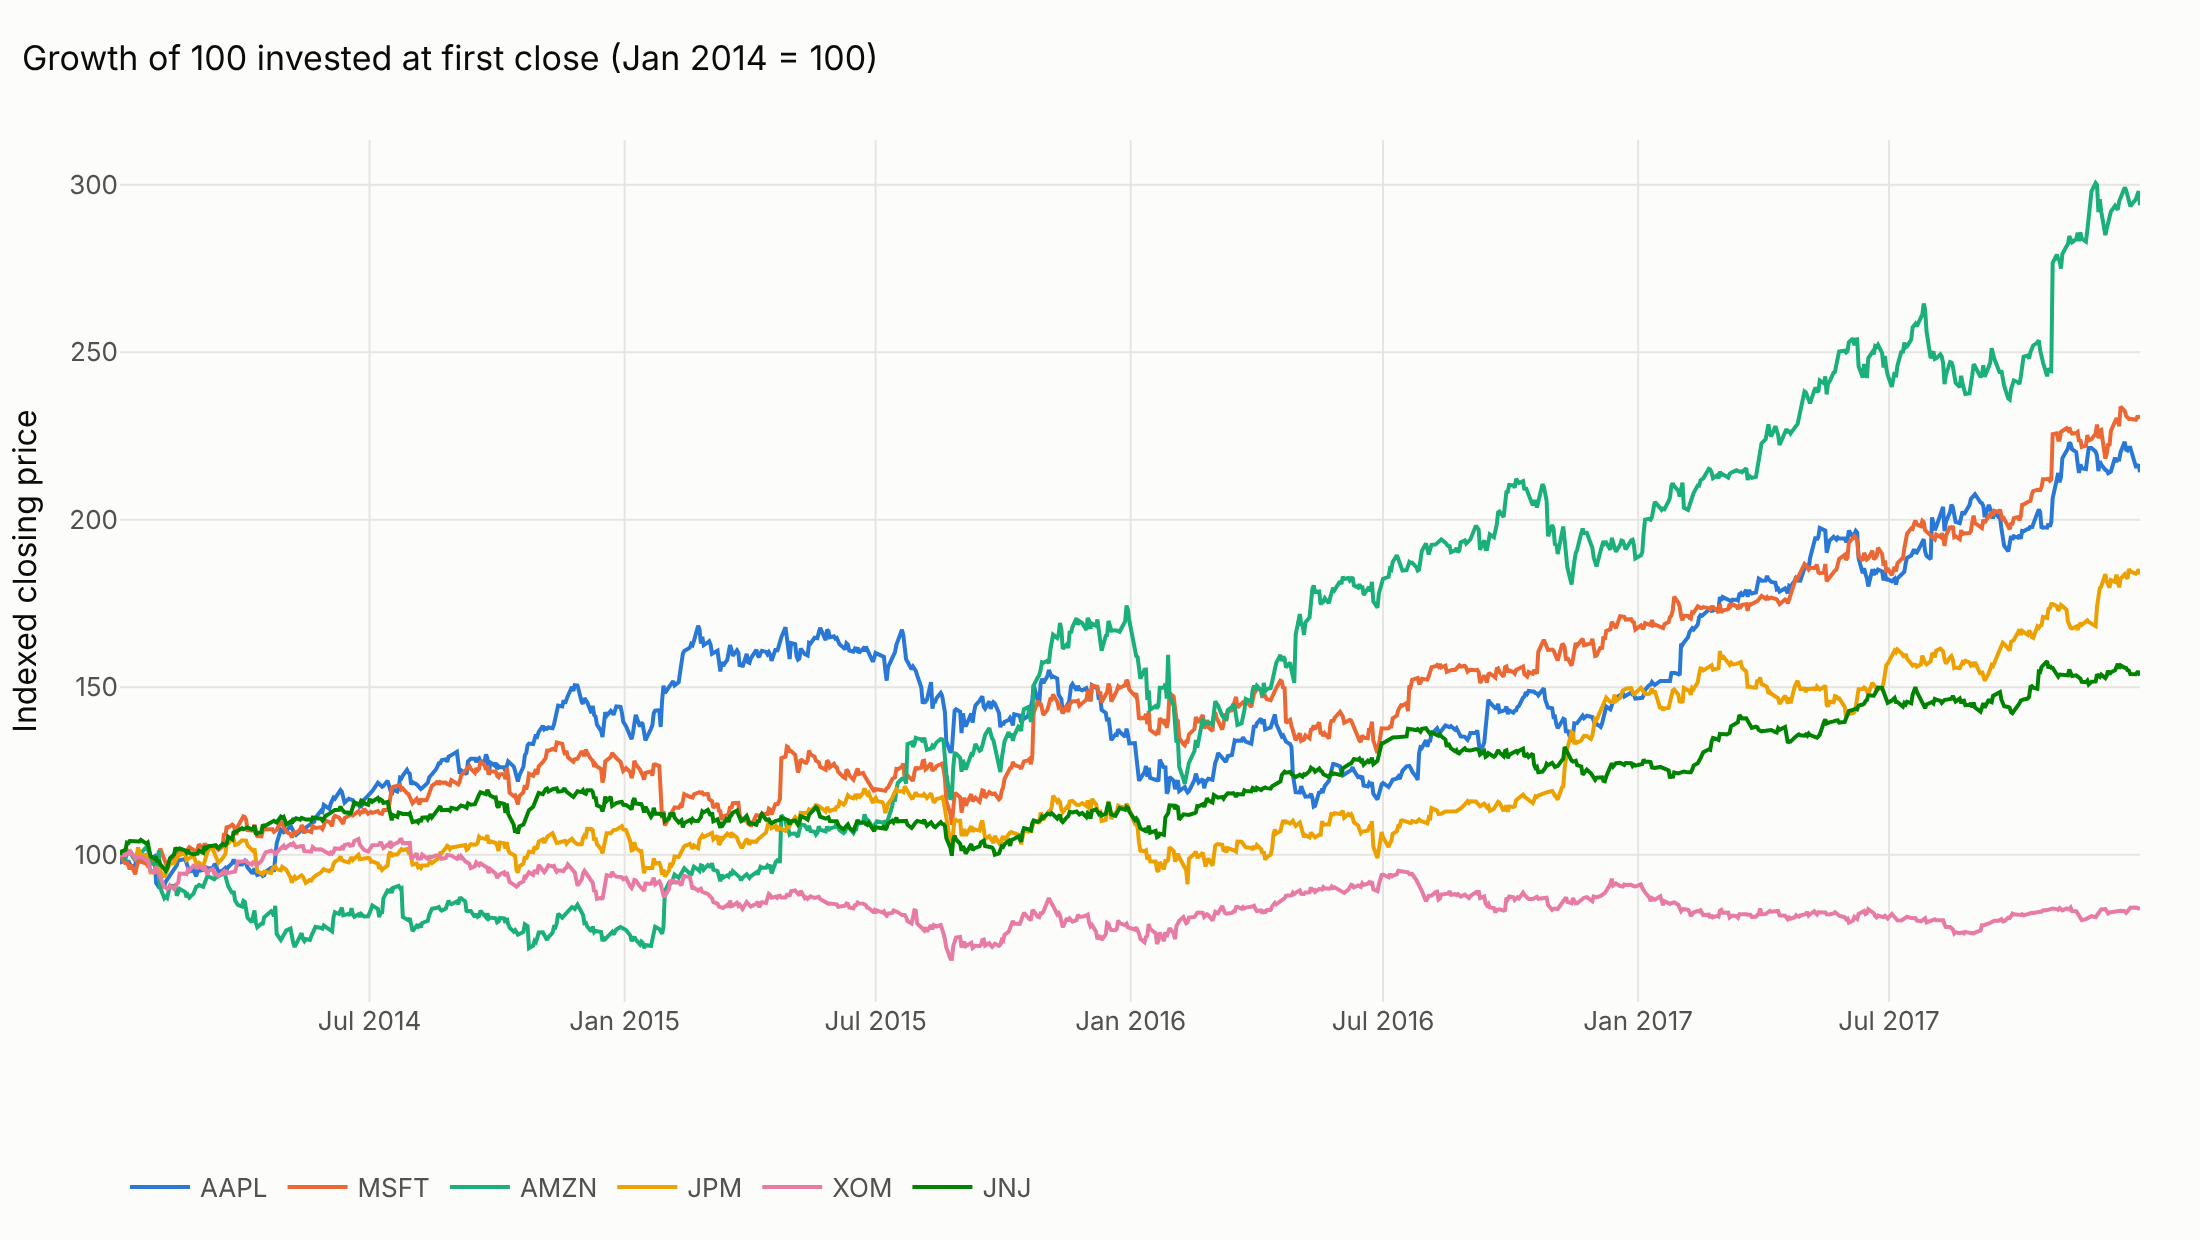

02_top_bottom_total_return.png


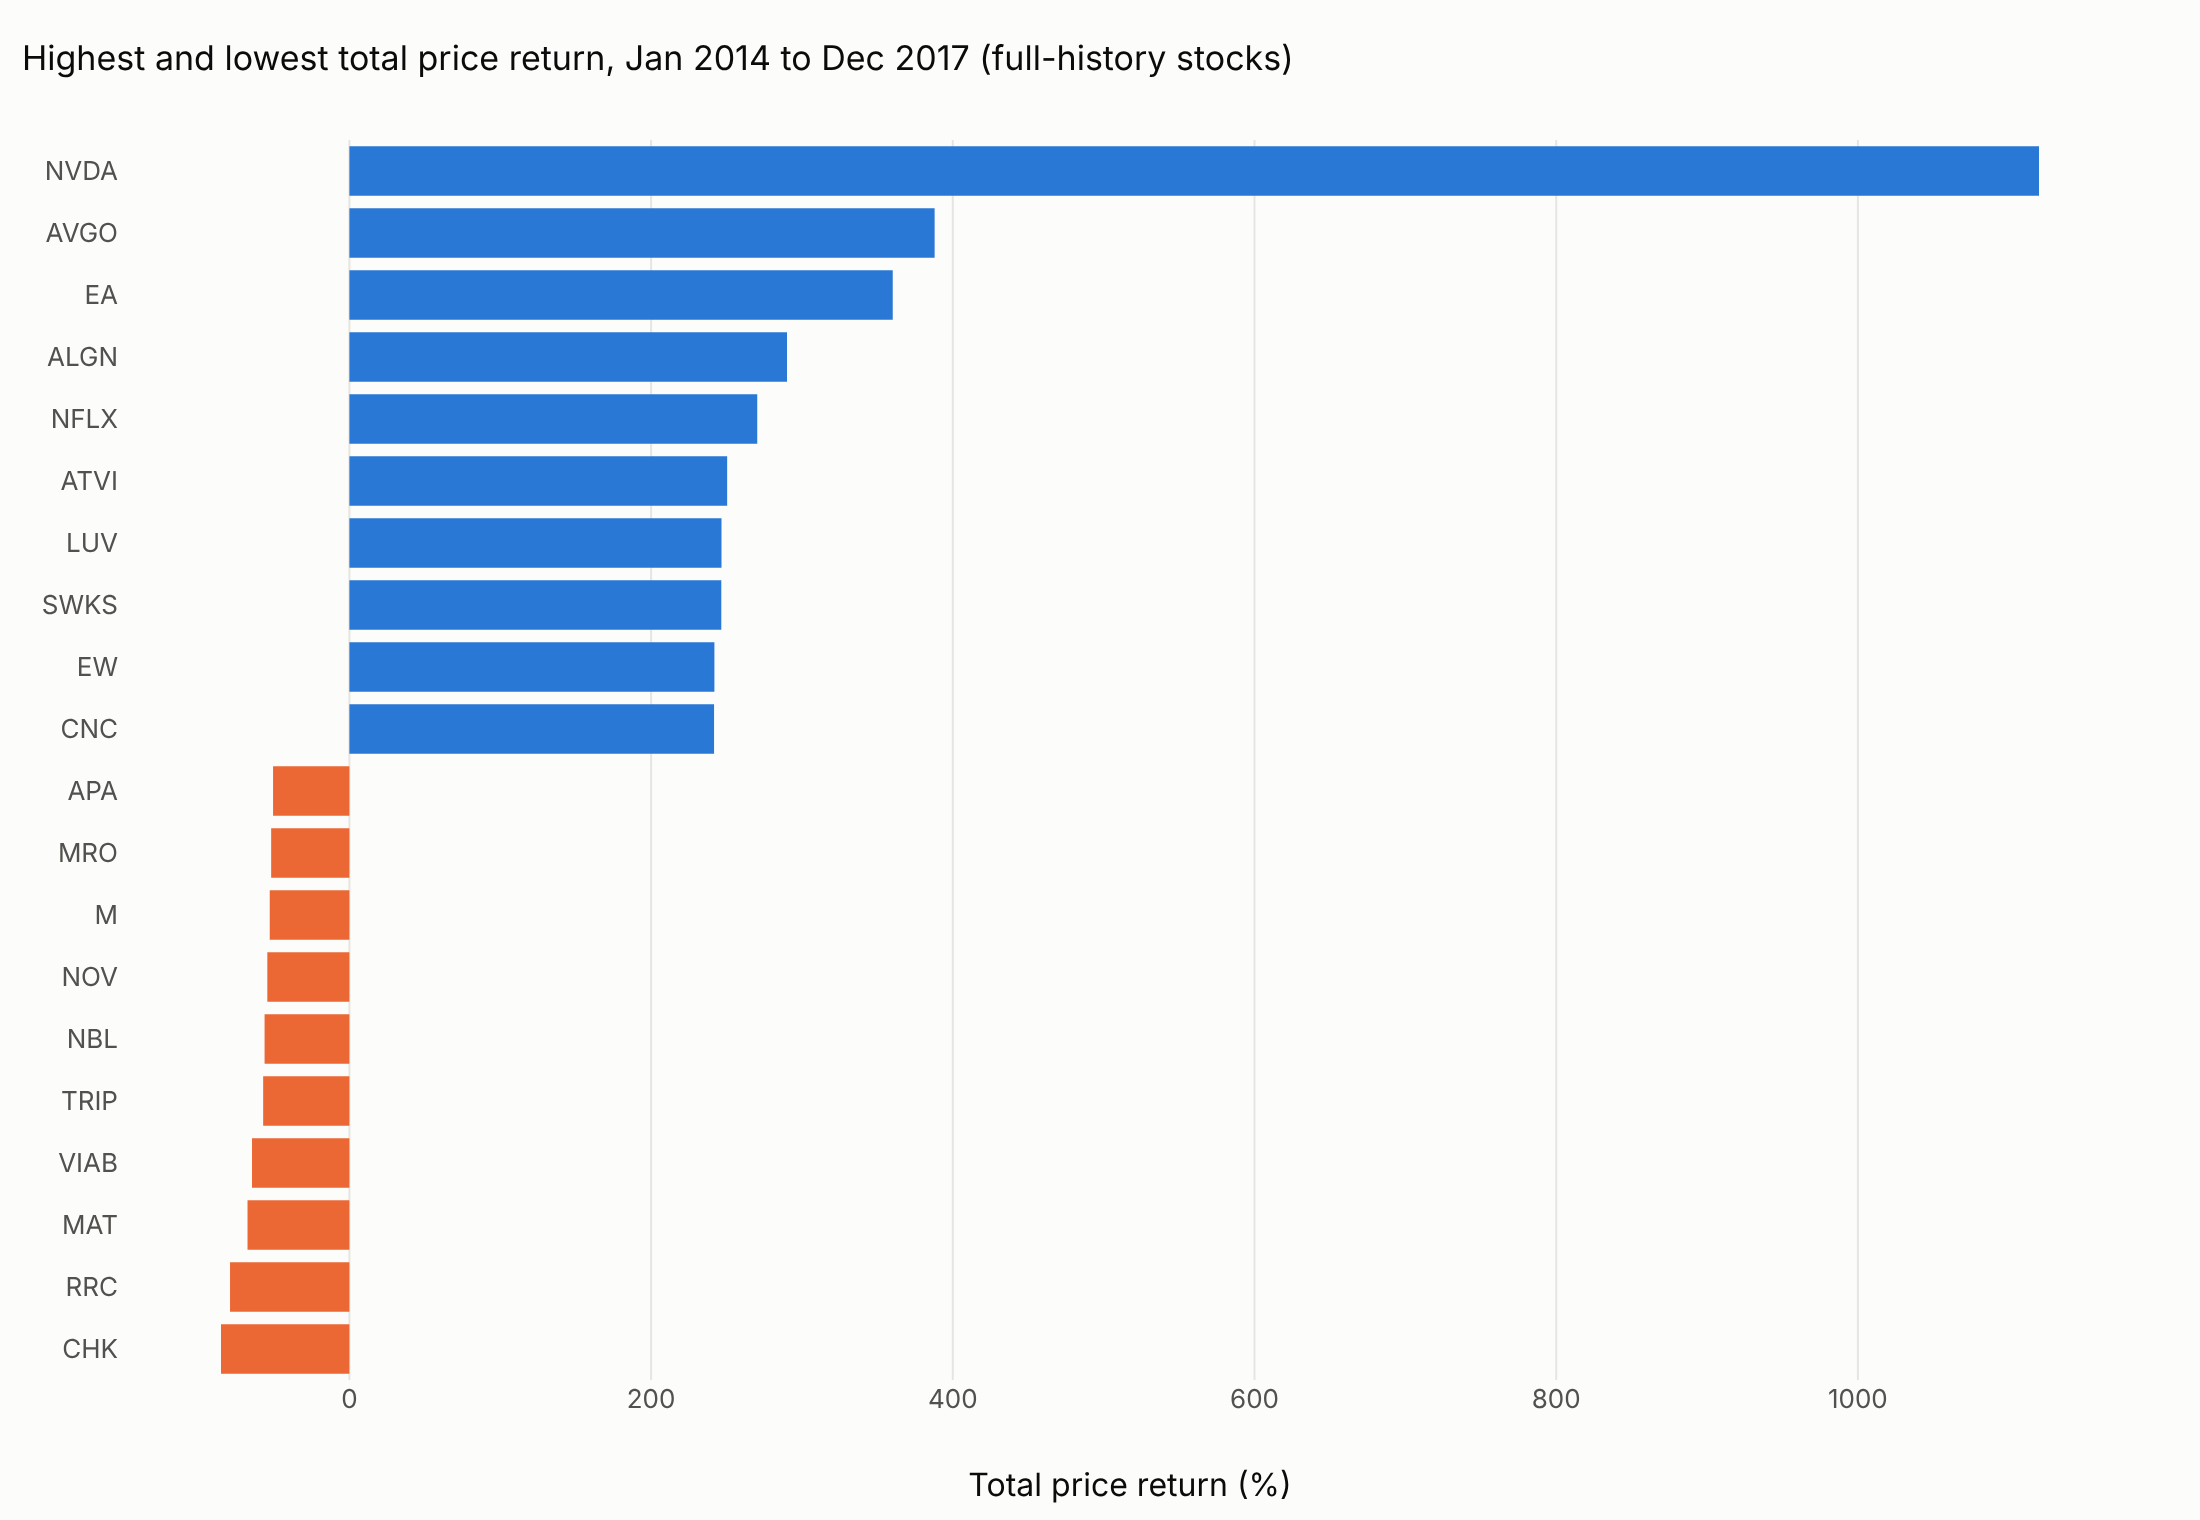

03_risk_vs_return.png


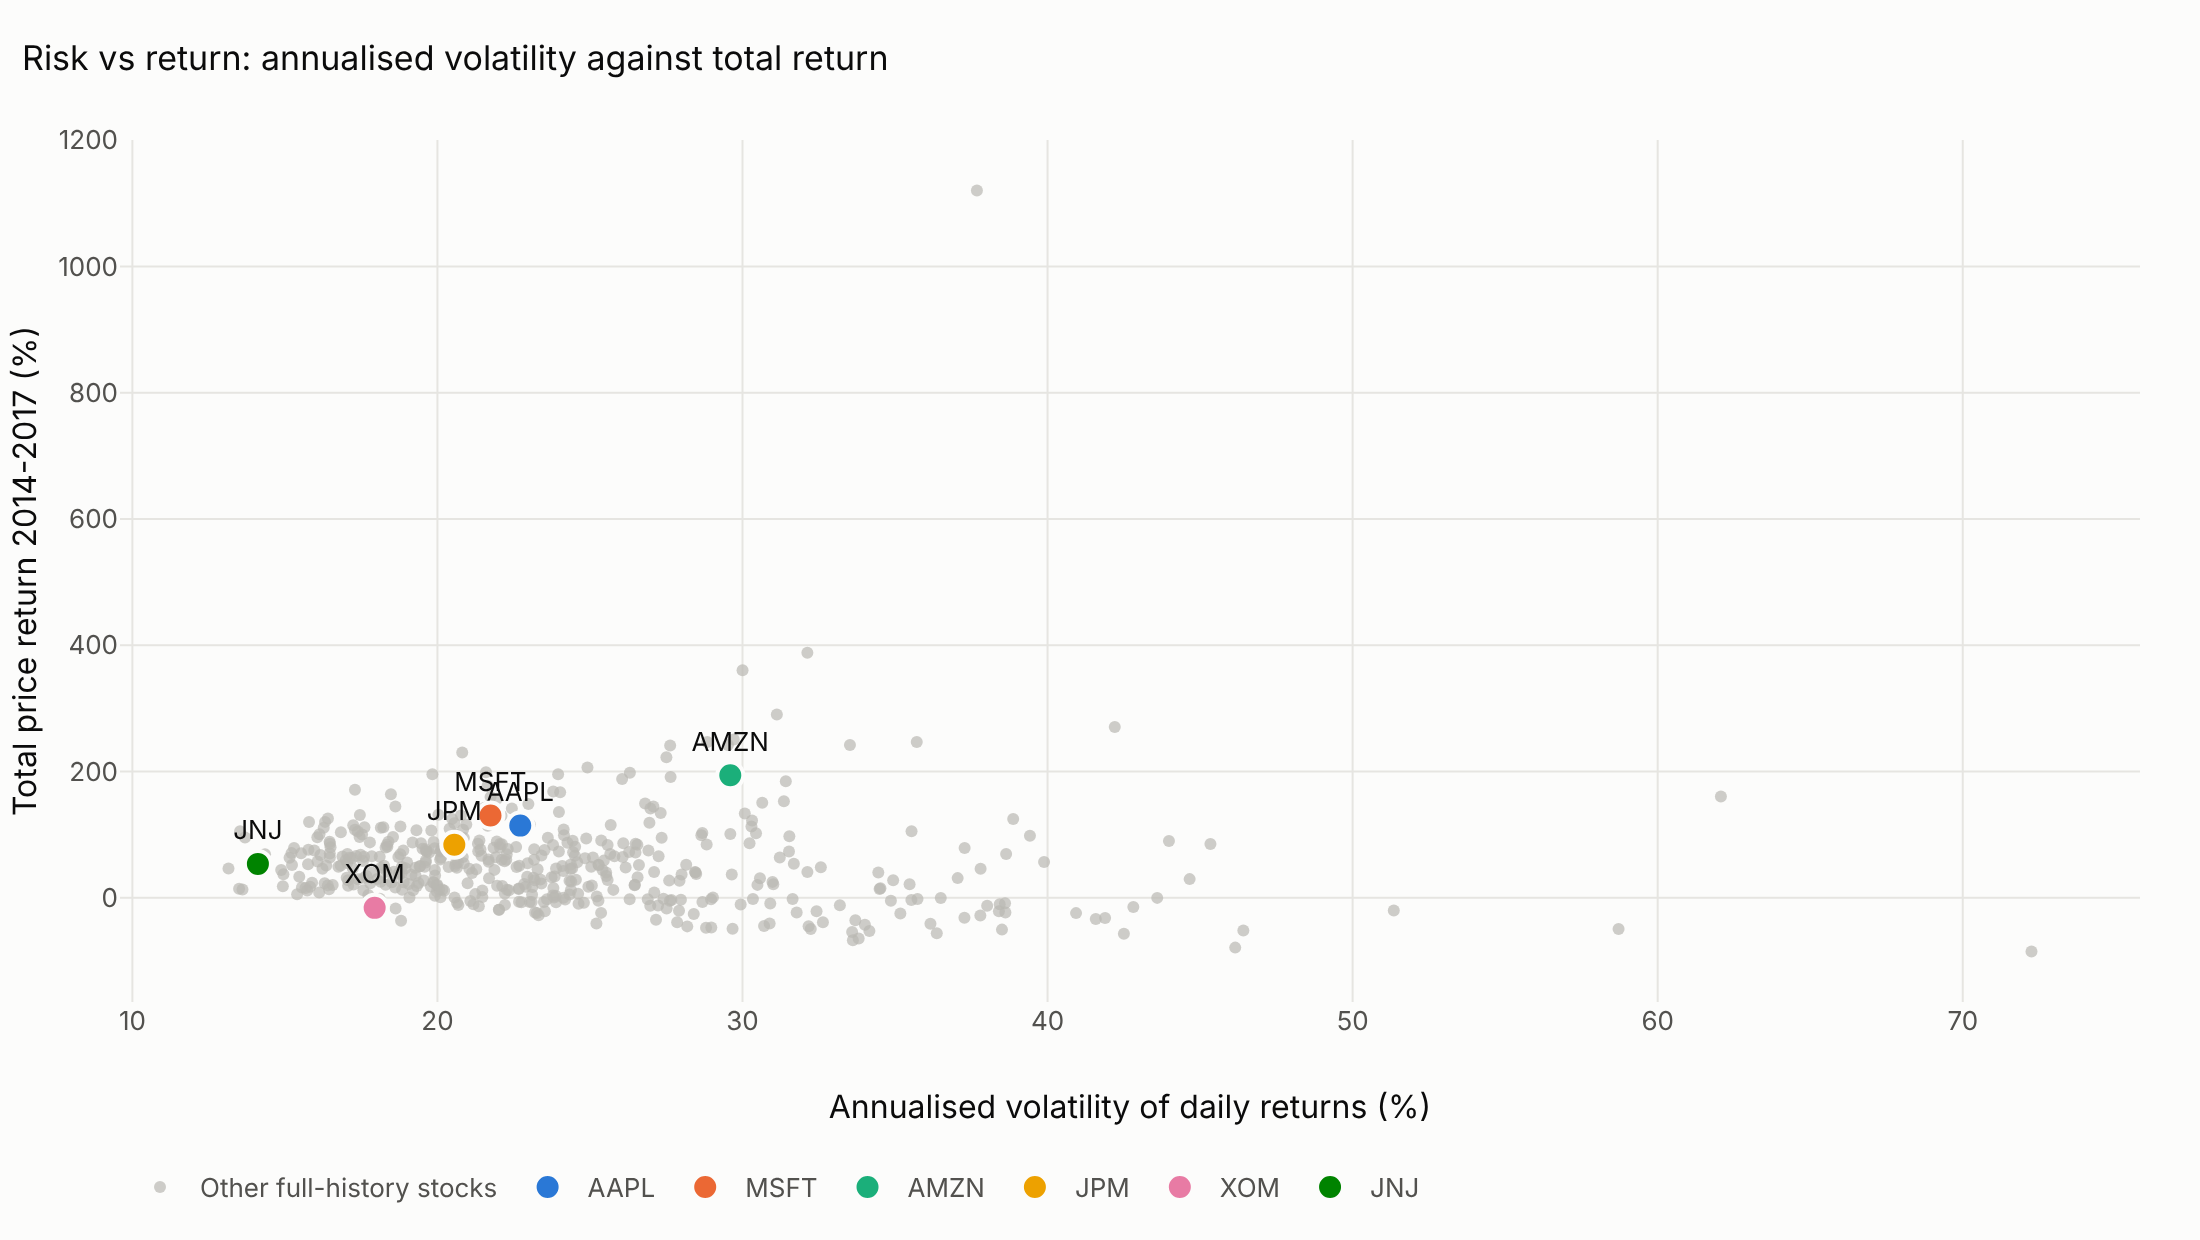

04_return_distribution.png


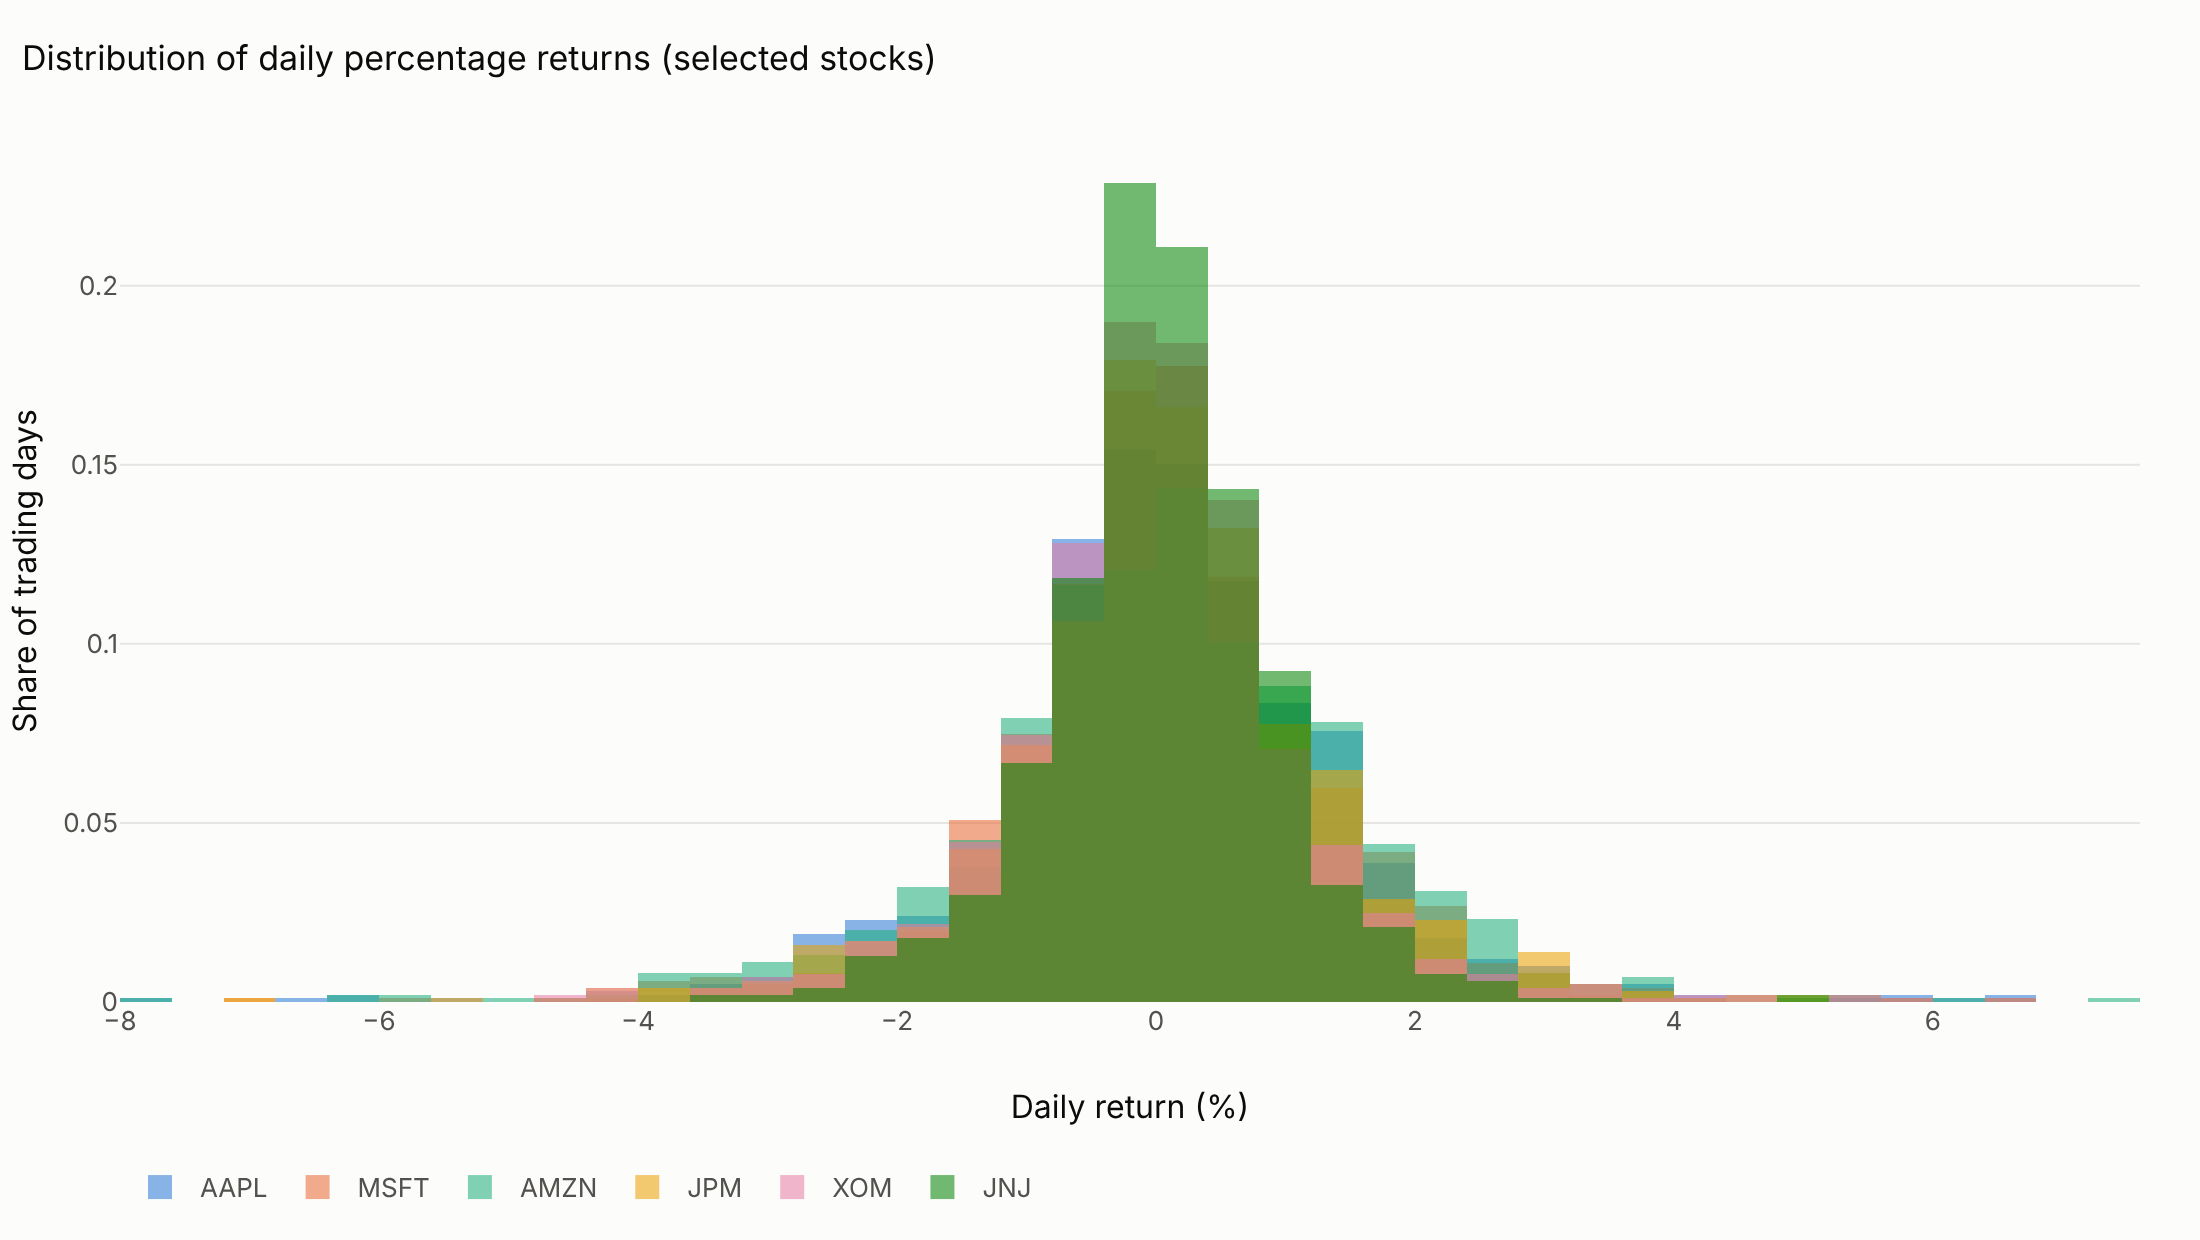

05_average_volume.png


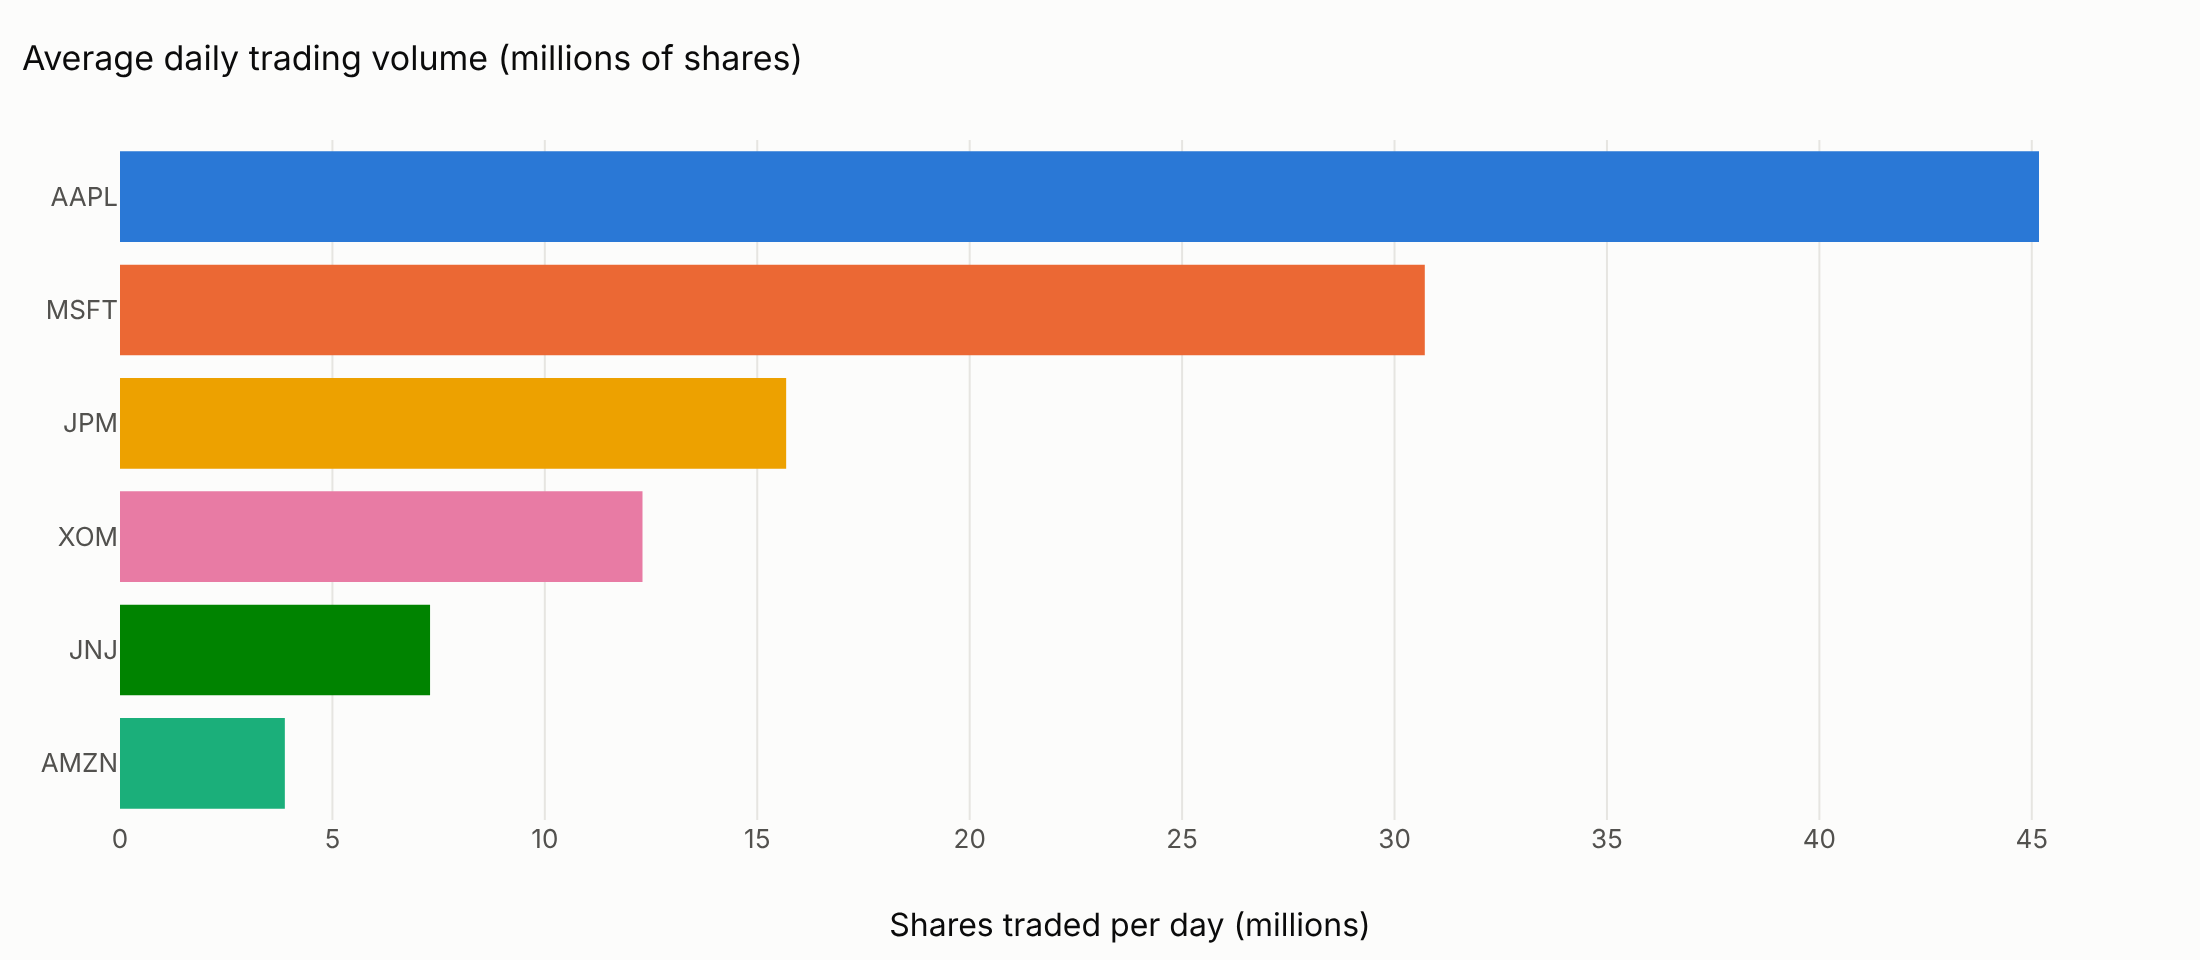

06_return_correlation.png


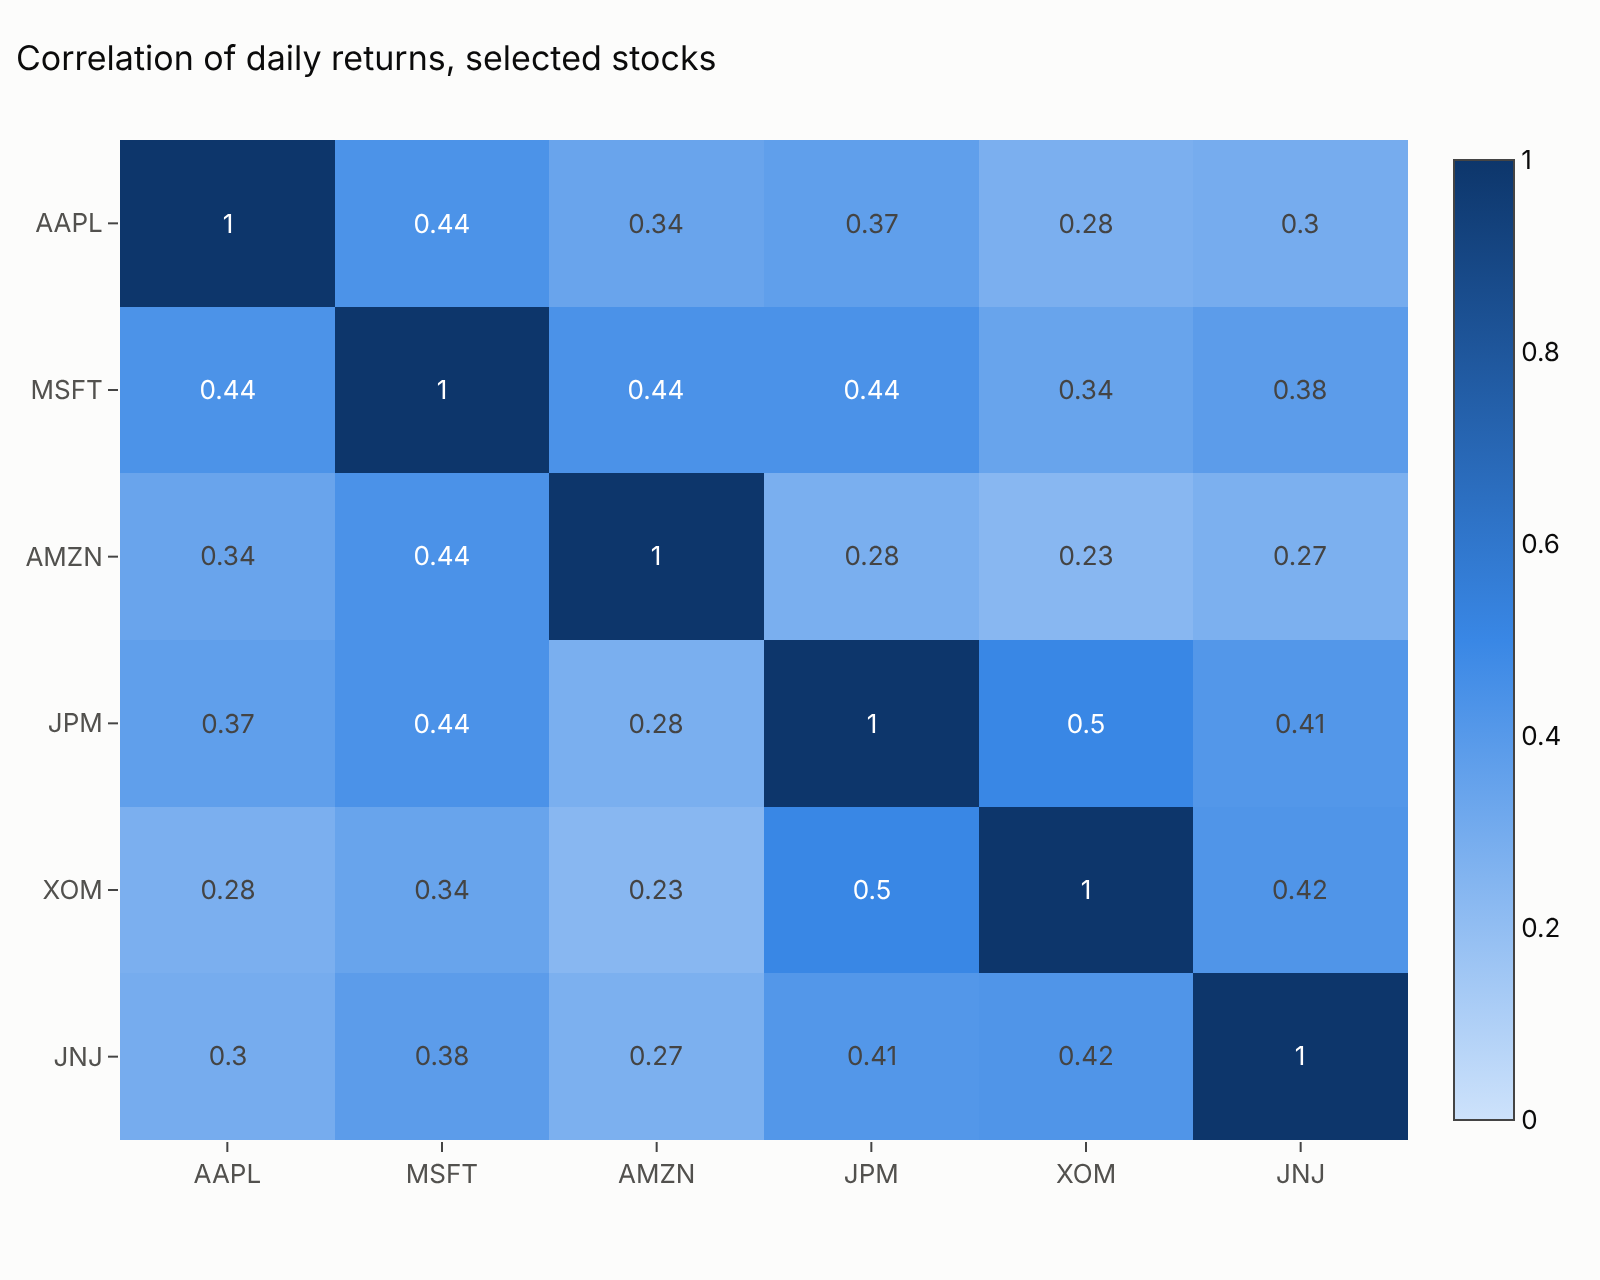

07_yearly_returns.png


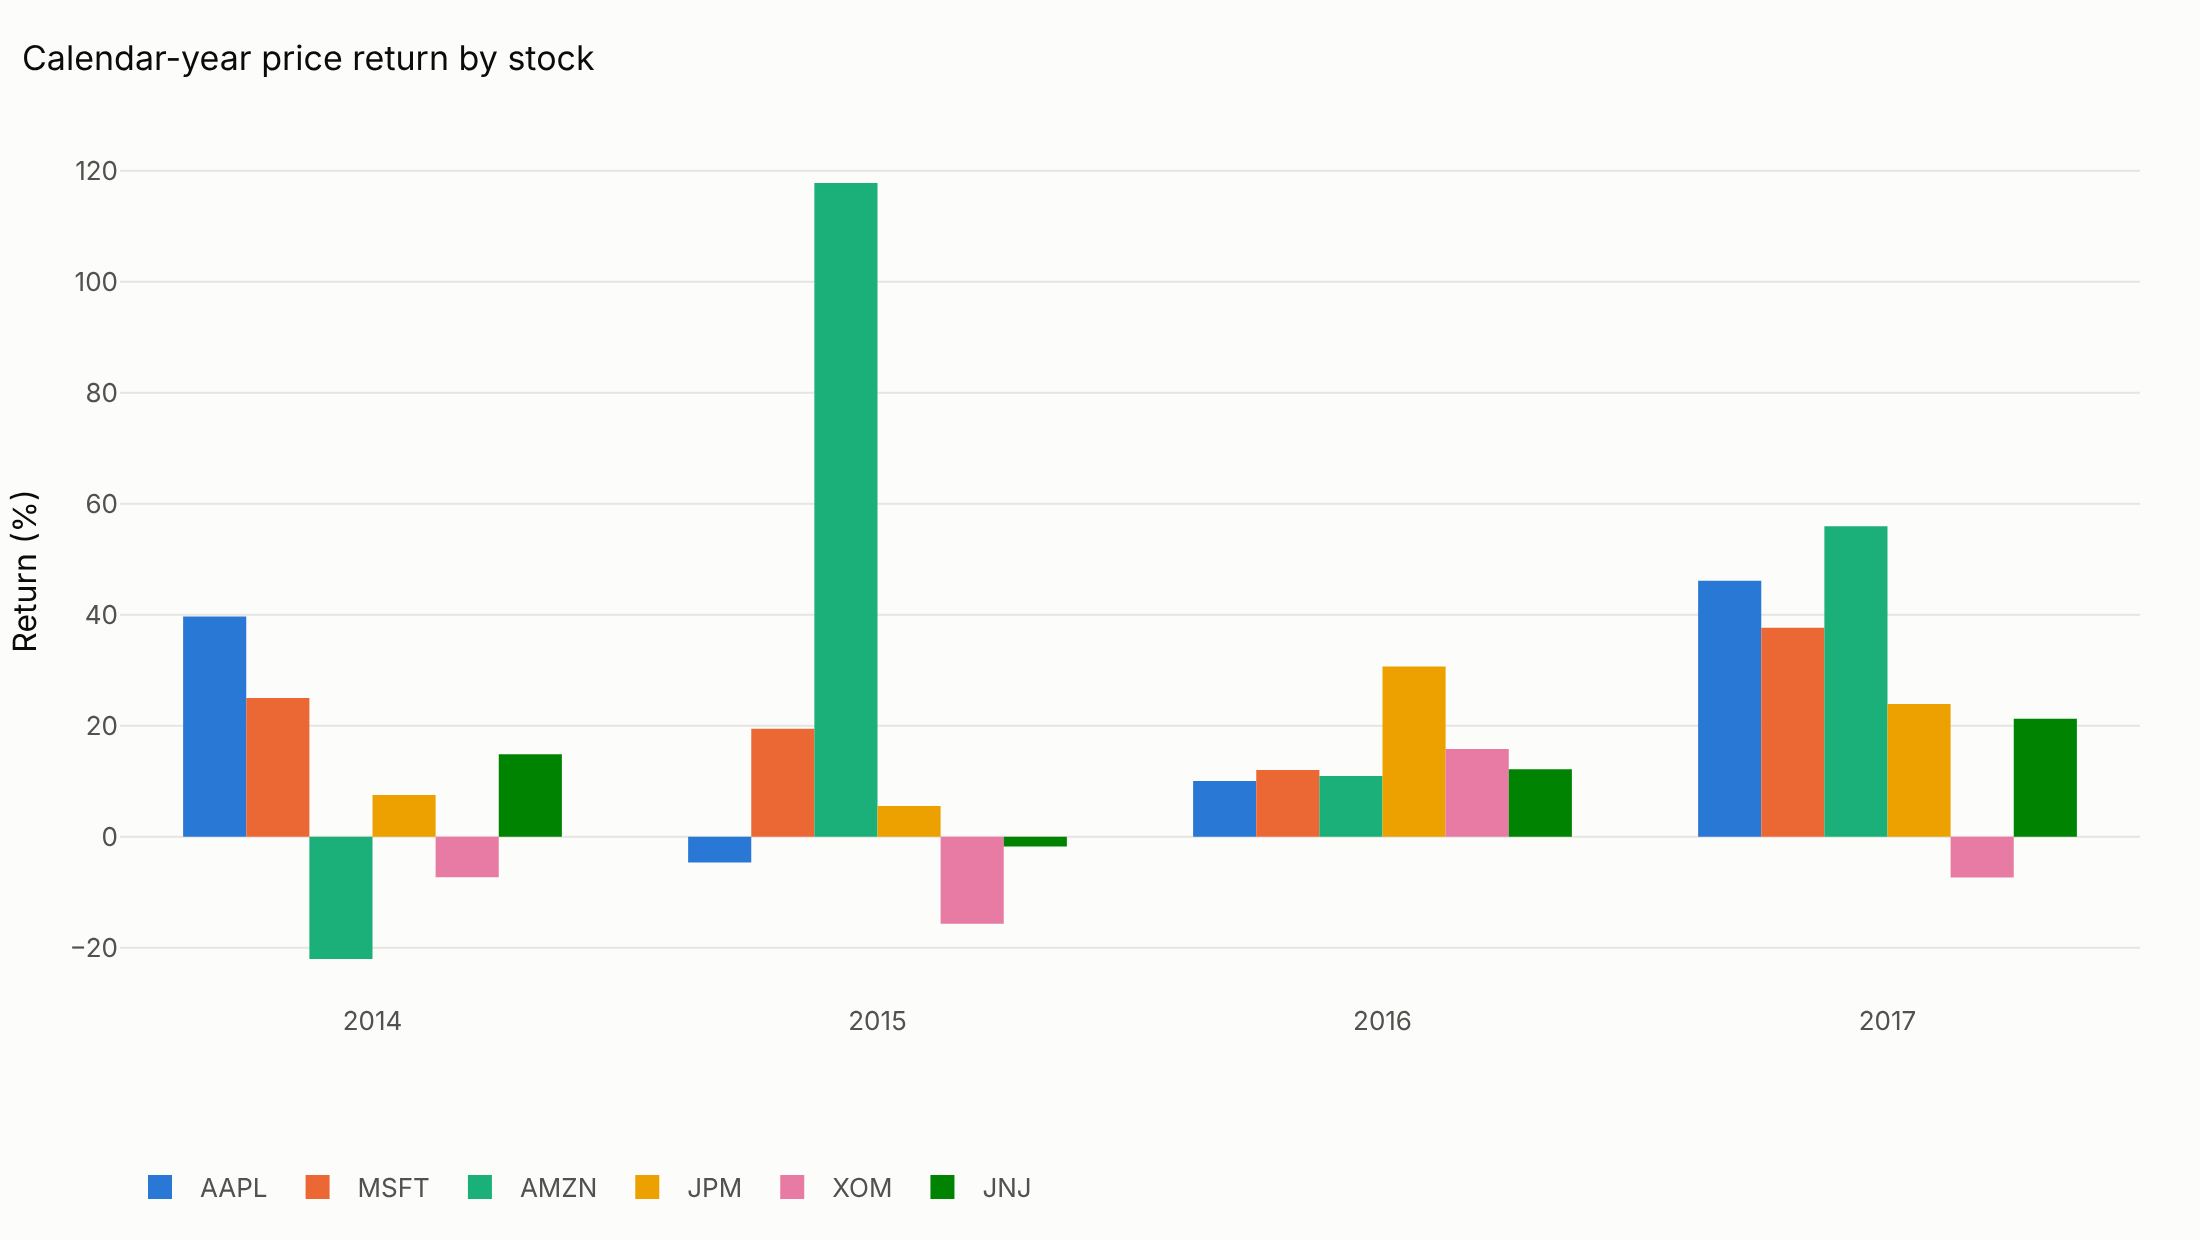

08_moving_averages_aapl.png


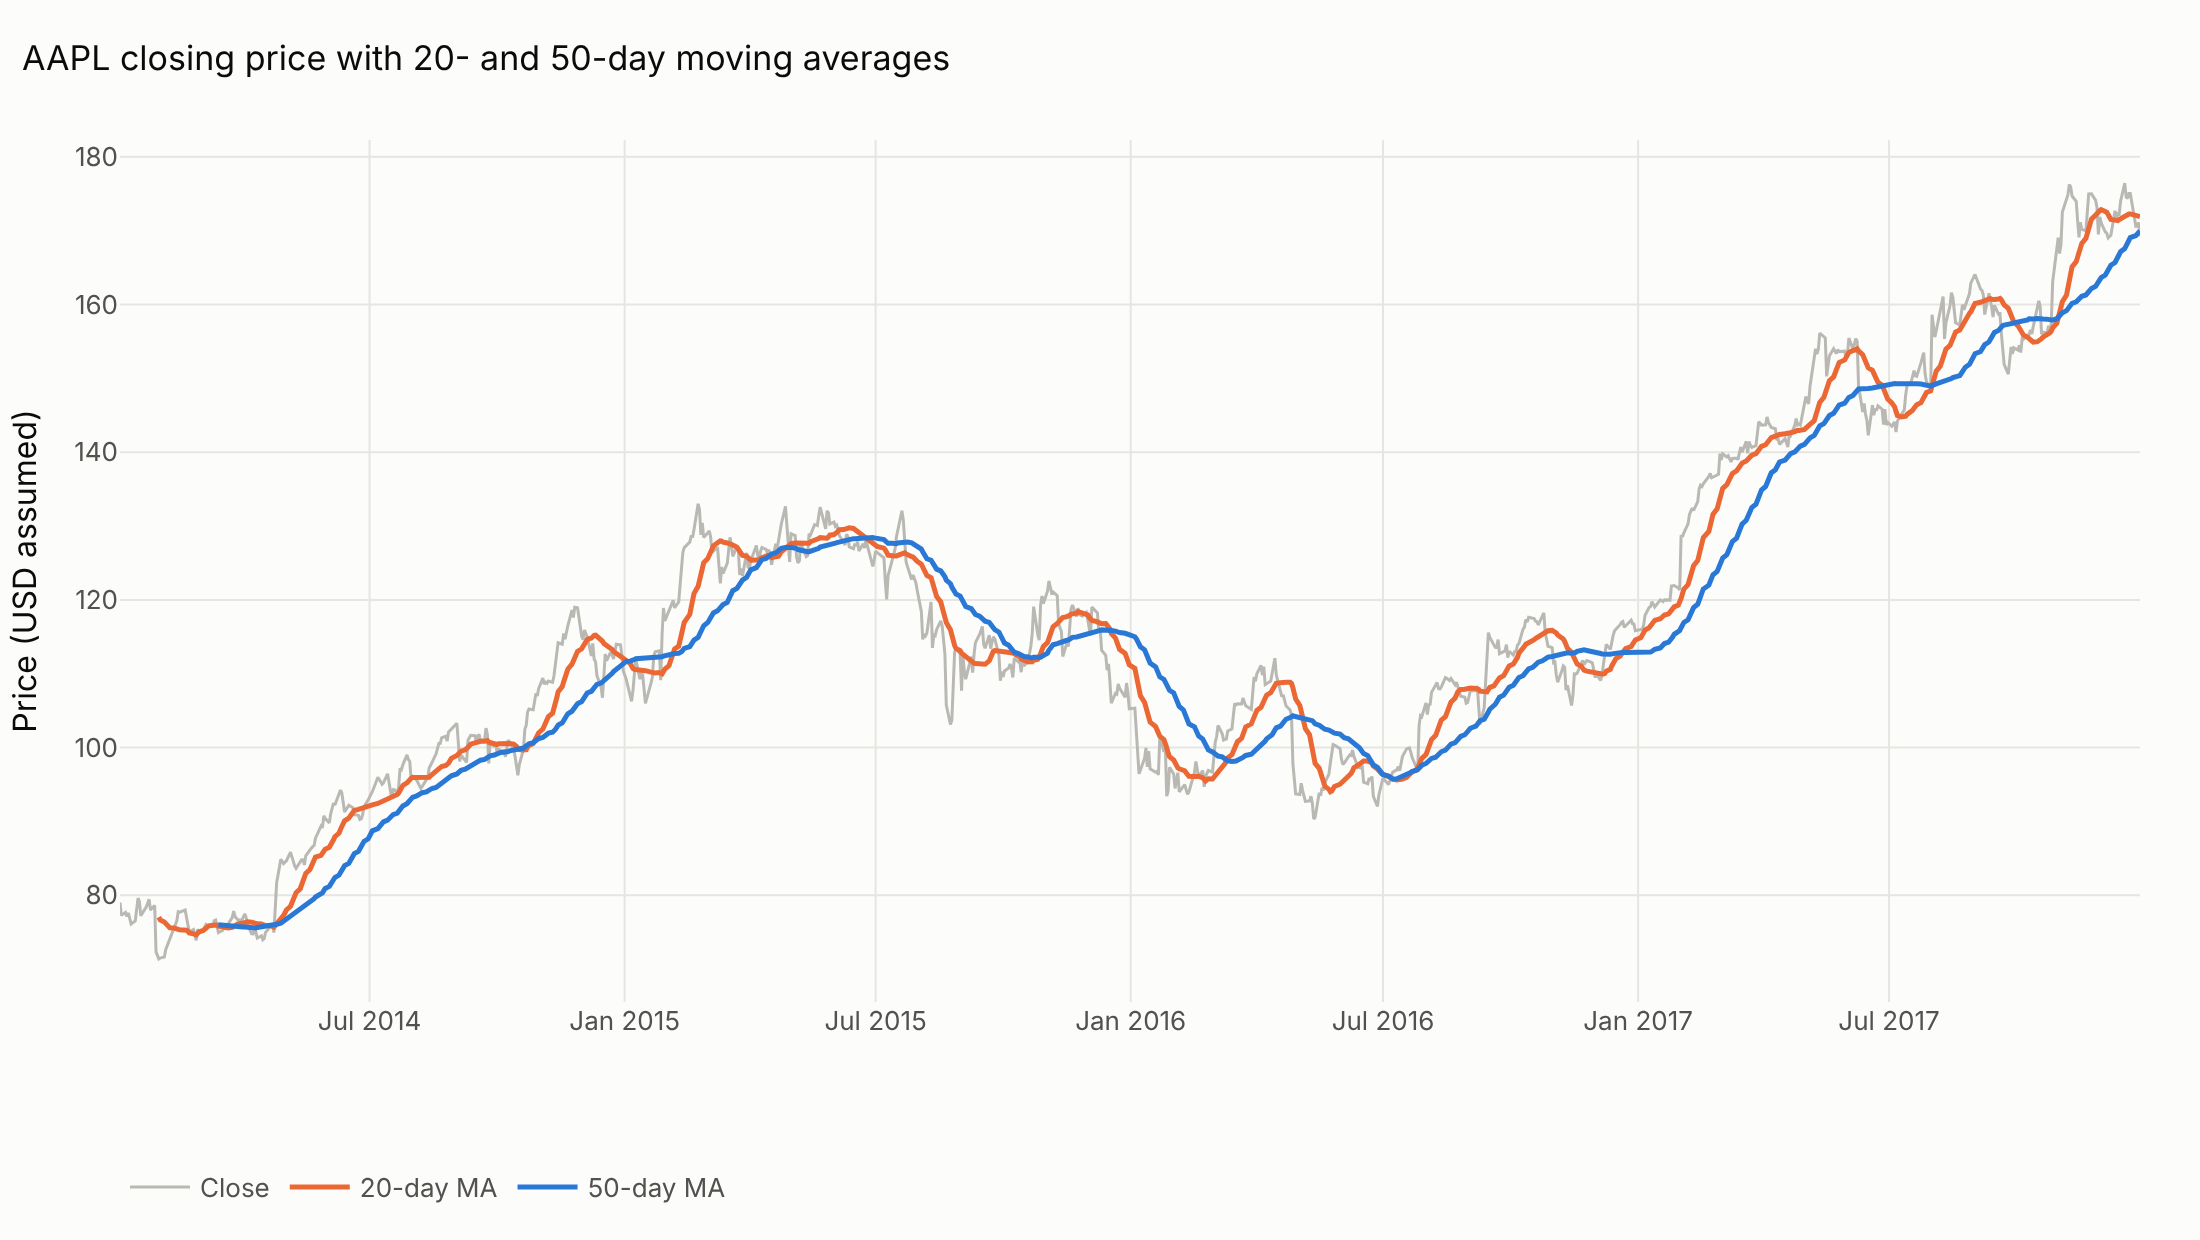

09_rolling_volatility.png


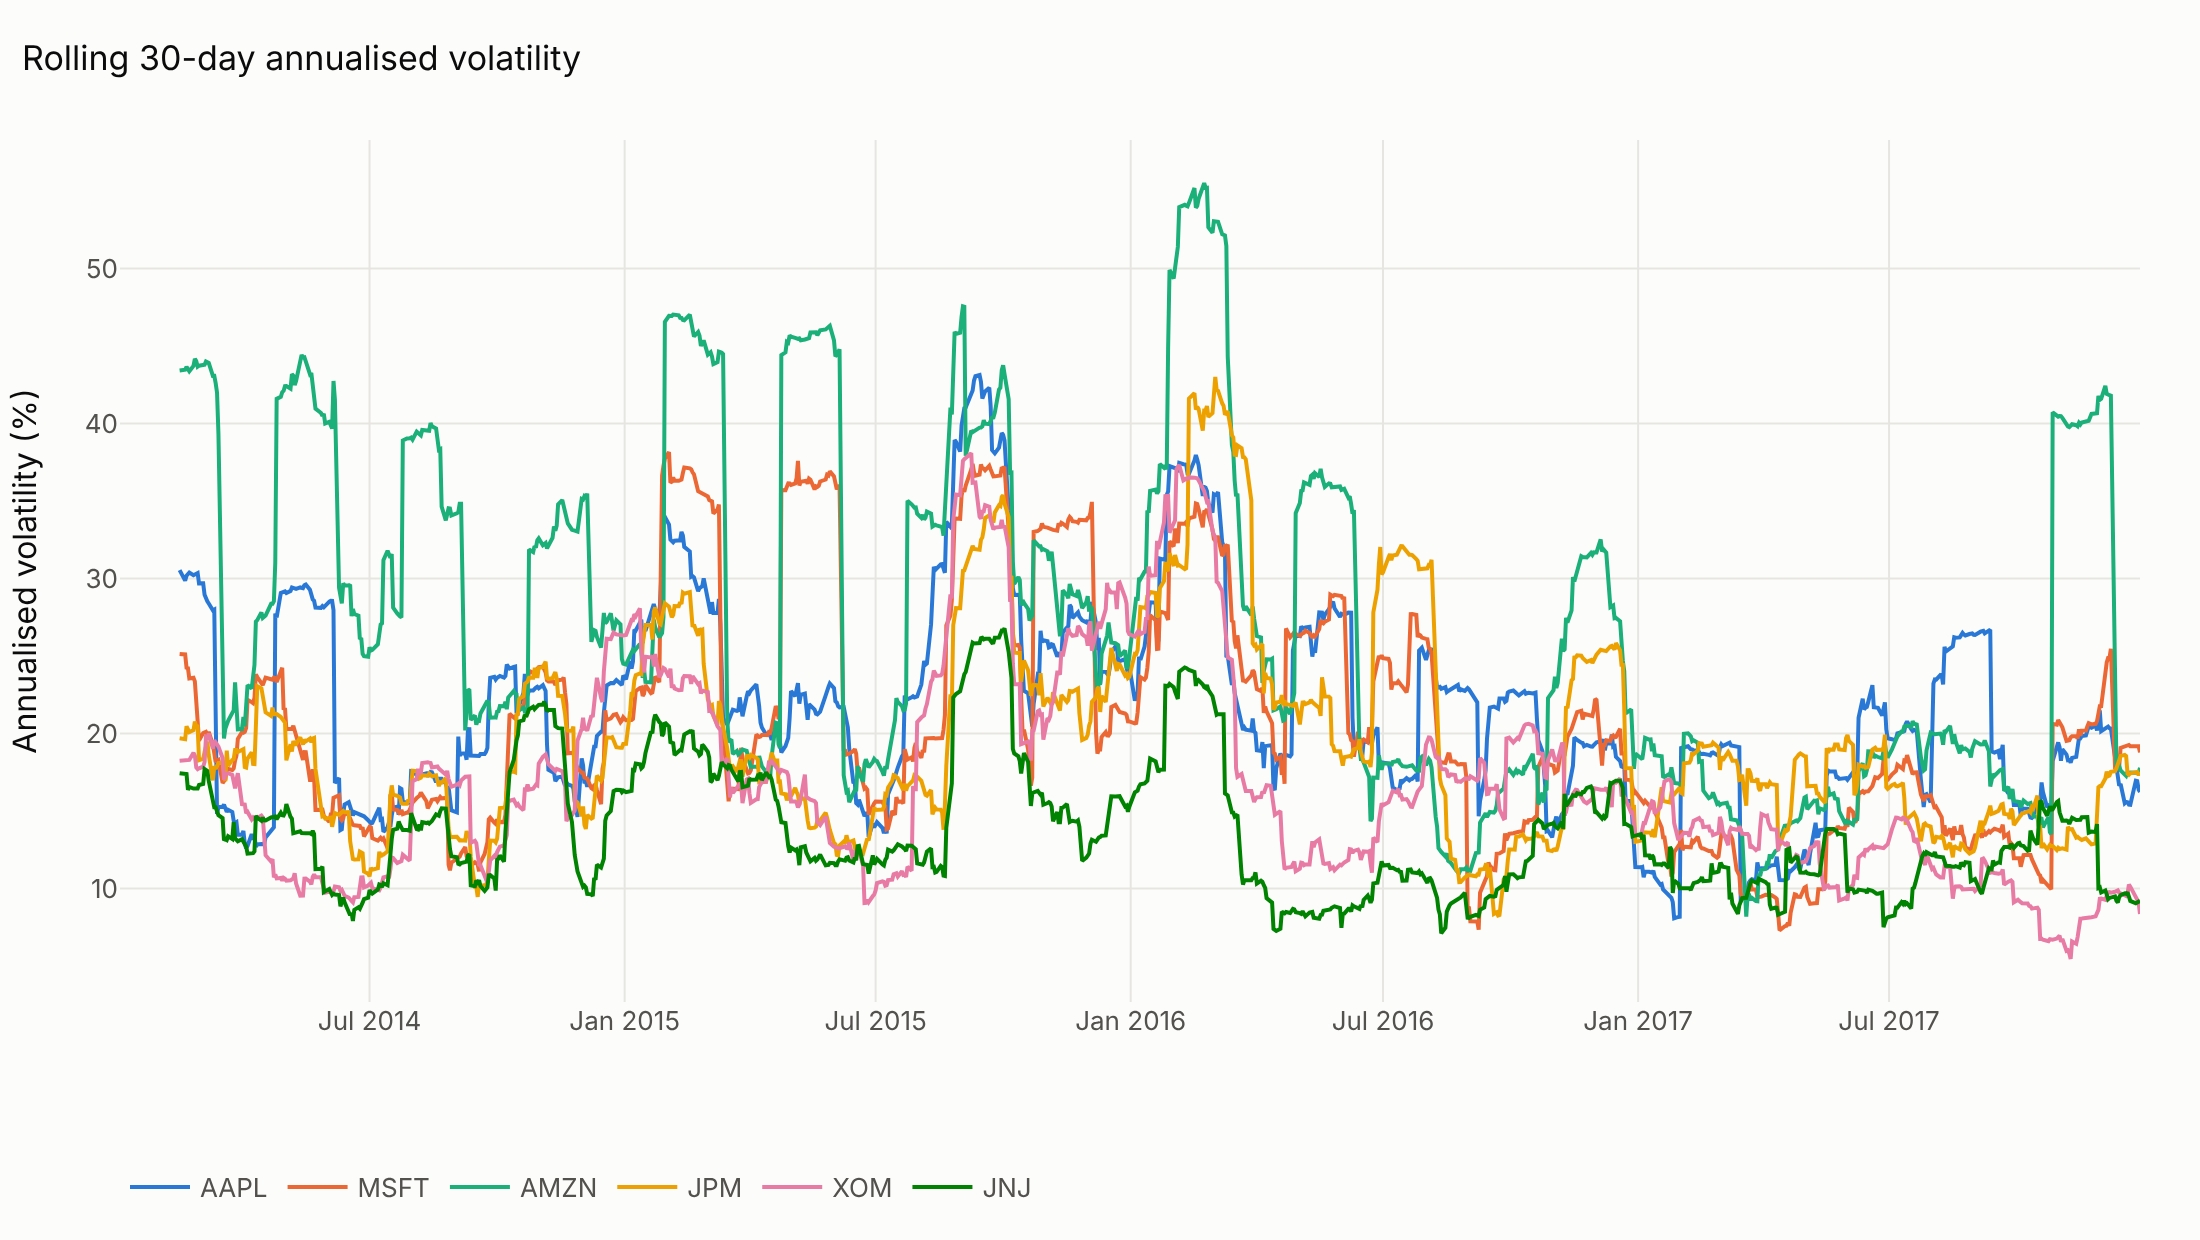

In [9]:
import glob
for p in sorted(glob.glob('visualisations/*.png')):
    print(os.path.basename(p)); display(Image(p, width=900))

Interactive versions of each chart are in `visualisations/*.html`.

## 5. Dashboard validation (Task 6)

In [10]:
!python validation/03_validate_dashboard.py 2>&1 | grep -v Warning

PASS  V1a record count - csv rows 497,464 vs dashboard 497,464
PASS  V1b symbol count - 505 symbols
PASS  V1c total shares traded - 2,116,051,738,554
PASS  V1d KPI average close (selected) - $176.34 vs $176.34


PASS  V2 daily return formula - max abs difference across 6 stocks x 1,006 days = 0.00e+00 percentage points


PASS  V3 20-day moving average - max abs difference 4.55e-13; first 19 values blank (no look-ahead, no zero fill)


PASS  V3 5-day moving average - max abs difference 2.27e-13; first 4 values blank (no look-ahead, no zero fill)
PASS  V4a symbol filter - traces ['JPM', 'MSFT']
PASS  V4b date filter - 504 points, 2016-01-04..2016-12-30, expected 504
PASS  V4c six-series cap - 9 symbols selected -> 6 plotted


PASS  V4d empty selection safe - no traces, message shown instead of error
PASS  V5a rolling 30-day volatility - XOM last value 8.3487 vs manual 8.3487
PASS  V5b average volume - max abs difference 0.00e+00 million shares
PASS  V6 total return - max abs difference 0.0000 percentage points (stocks without flagged days)


interior missing dates: {'DHR': 13, 'ES': 10, 'ICE': 1, 'O': 13, 'REGN': 1, 'VRTX': 1, 'WRK': 1, 'BHF': 1}


All checks compare the dashboard's figure builders with an independent recalculation from the raw CSV (csv module + NumPy). Full table: `validation/validation_evidence.md`.

## 6. Findings and recommendations
See `docs/executive_summary.md` for the seven findings and four recommendations, each tied to the evidence above.